In [2]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [3]:
#!/usr/bin/env python3

import gtsam
import gtsam_unstable
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree

# Local imports
import common.FGVizHelpers as fgtools
from multiSession.SessionManager import SessionManager
from multiSession.SessionUpdater import SessionUpdater

from sparcification.NFR import GraphSparsification
from ros2.readFromRosbags import GroundTruthLoader, ReadTopicsFromRosbag



Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Load and plot original graph

PriorSessionSymbols have been updated to ['A']
AddToPriorSymbol has been updated to B
PriorSessionSymbols have been updated to ['A']
AddToPriorSymbol has been updated to B
495


Text(0.5, 1.0, 'Aligned Via GPS Only')

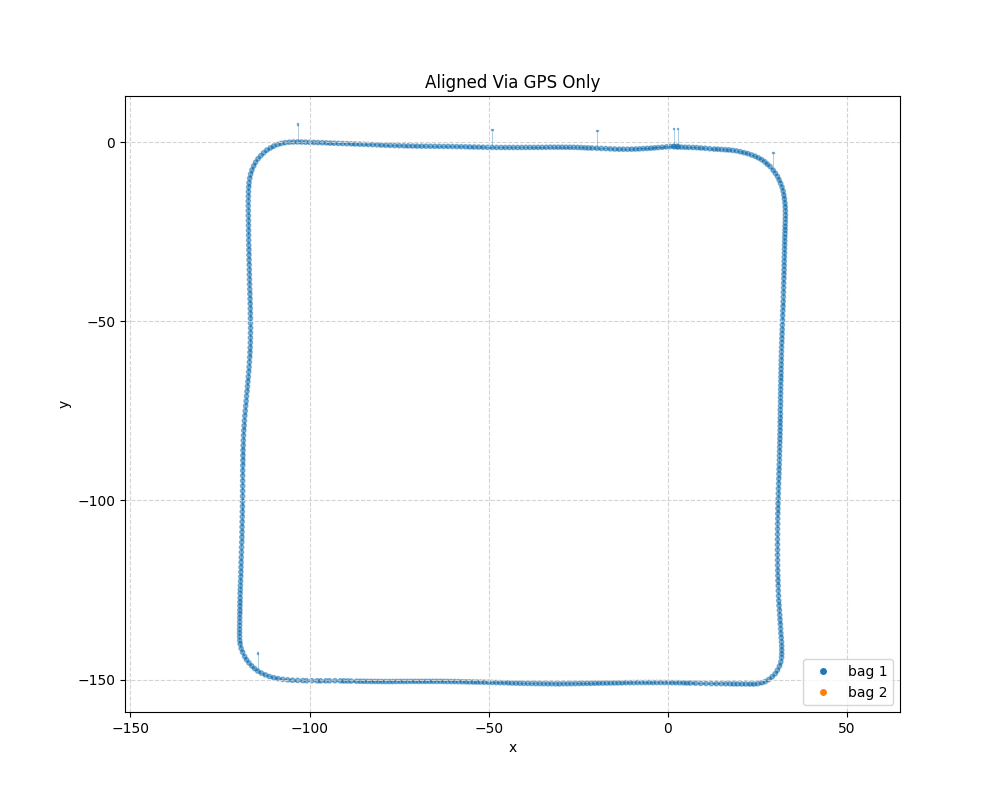

In [13]:
# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
directory1 = Path("../../results/urban/around_block_initial/")
directory2 = Path("../../results/urban/around_block_short_reconnect/")
directory3 = Path("../../results/urban/quick_map_disconnect/")
fileName = "fullSavedGraph.g2o"

session1 = SessionManager(directory1 / fileName)
session2 = SessionManager(directory2 / fileName)
# session3 = SessionManager(directory3 / fileName)

session1.UpdateISAM2()
session2.UpdateISAM2()
# session3.UpdateISAM2()

session1.LoadScans(directory1 / "Scans")
session2.LoadScans(directory2 / "Scans")
# session3.LoadScans(directory3 / "Scans")

bag_colors = ['tab:blue', 'tab:orange', 'tab:green']

print(session1.graph.size())

ax = fgtools.plot_graph(session1.graph, session1.values, color_override=bag_colors[0], alpha=0.5, addKeyLabels=False)
# fgtools.plot_graph_covariances(session1.values.keys(), session1.graph, session1.values, ax=ax)

# fgtools.plot_graph(session2.graph, session2.values, ax=ax, color_override=bag_colors[1], alpha=0.5)
# fgtools.plot_graph_covariances(session2.values.keys(), session2.graph, session2.values, ax=ax)

# fgtools.plot_graph(session3.graph, session3.values, ax=ax, color_override=bag_colors[2], alpha=0.5)
# fgtools.plot_graph_covariances(session3.values.keys(), session3.graph, session3.values, ax=ax)

legendElements = [
                    Line2D([0],[0], marker='o', color='w', label="bag 1", markerfacecolor=bag_colors[0]),
                    Line2D([0],[0], marker='o', color='w', label="bag 2", markerfacecolor=bag_colors[1]),
                    # Line2D([0],[0], marker='o', color='w', label="bag 3", markerfacecolor=bag_colors[2]),
                ]
ax.legend(handles=legendElements, loc='lower right')
ax.set_title("Aligned Via GPS Only")

# globalMap1 = session1.CreateGlobalPCD((1, 0, 0))
# globalMap2 = session2.CreateGlobalPCD((0, 1, 0))
# globalMap3 = session3.CreateGlobalPCD((0, 0, 1))

# o3d.visualization.draw_geometries([globalMap1, globalMap2, globalMap3])


In [29]:
import gtsam_unstable
graph = session1.graph
values = session1.values
ret = gtsam_unstable.serializeGraphToFile(graph, "serialGraphReal.gtsam")
print(ret)
ret = gtsam_unstable.serializeValuesToFile(values, "serialValuesReal.gtsam")
print(ret)

True
True


In [30]:
new_graph = gtsam_unstable.deserializeGraphFromFile("serialGraphReal.gtsam")
new_values = gtsam_unstable.deserializeValuesFromFile("serialValuesReal.gtsam")
print(graph.equals(new_graph, 1e-6))
print(values.equals(new_values, 1e-6))

True
True


<Axes: xlabel='x', ylabel='y'>

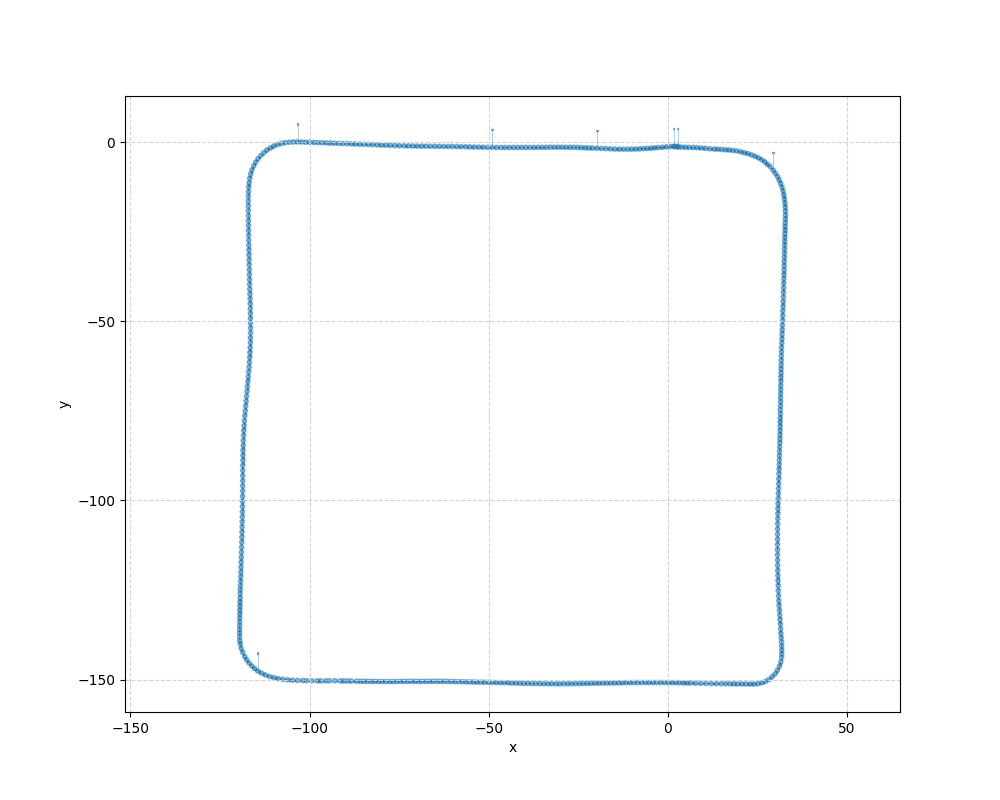

In [31]:
fgtools.plot_graph(new_graph, new_values, color_override=bag_colors[0], alpha=0.5, addKeyLabels=False)

In [7]:
from common.weighted_pose_graph_class import WeightedPoseGraph

wpg = WeightedPoseGraph(session1.graph, session1.values)

## Test for Python Binding

In [4]:
import numpy as np
import gtsam
from gtsam import (
    NonlinearFactorGraph,
    Values,
    PriorFactorDouble,
    BetweenFactorDouble,
    noiseModel,
    FixedLagSmoother
)
from gtsam import IncrementalFixedLagSmoother
from gtsam.symbol_shorthand import X



# ---------------------------------------------------------
# Fixed lag size (seconds)
# Variables older than current_time - lag are marginalized
# ---------------------------------------------------------
lag = 5.0

smoother = IncrementalFixedLagSmoother(lag)

# Noise models
prior_noise = noiseModel.Isotropic.Sigma(1, 0.1)
odom_noise = noiseModel.Isotropic.Sigma(1, 0.2)
meas_noise = noiseModel.Isotropic.Sigma(1, 0.5)

dt = 1.0
velocity = 1.0

current_time = 0.0

for k in range(15):

    graph = NonlinearFactorGraph()
    values = Values()
    timestamps = {}

    key = X(k)

    # -----------------------------------------------------
    # Simulated ground truth
    # x_k = v * t
    # -----------------------------------------------------
    true_position = velocity * current_time

    # noisy measurement
    measured_position = (
        true_position + np.random.randn() * 0.5
    )

    # -----------------------------------------------------
    # Initialize estimate
    # -----------------------------------------------------
    initial_guess = measured_position
    values.insert(key, initial_guess)

    timestamps[key] = k

    # -----------------------------------------------------
    # Prior on first state
    # -----------------------------------------------------
    if k == 0:

        graph.add(
            PriorFactorDouble(
                key,
                0.0,
                prior_noise,
            )
        )

    else:

        prev_key = X(k - 1)

        # Constant velocity model:
        # x_k - x_{k-1} = v * dt
        graph.add(
            BetweenFactorDouble(
                prev_key,
                key,
                velocity * dt,
                odom_noise,
            )
        )

    # -----------------------------------------------------
    # Add measurement factor
    # This acts like a GPS measurement
    # -----------------------------------------------------
    graph.add(
        PriorFactorDouble(
            key,
            measured_position,
            meas_noise,
        )
    )

    # -----------------------------------------------------
    # Update smoother
    # -----------------------------------------------------
    smoother.update(
        graph,
        values,
        timestamps,
    )

    # -----------------------------------------------------
    # Get current estimate
    # -----------------------------------------------------
    result = smoother.calculateEstimate()

    print(f"\nTime step {k}")

    for j in range(max(0, k - 6), k + 1):

        test_key = X(j)

        if result.exists(test_key):

            estimate = result.atDouble(test_key)

            print(
                f"  x[{j}] = {estimate:.3f}"
            )

    current_time += dt





Time step 0
  x[0] = 0.016

Time step 1
  x[0] = 0.019
  x[1] = 1.034

Time step 2
  x[0] = 0.016
  x[1] = 1.018
  x[2] = 2.002

Time step 3
  x[0] = 0.011
  x[1] = 0.992
  x[2] = 1.951
  x[3] = 2.918

Time step 4
  x[0] = 0.016
  x[1] = 1.018
  x[2] = 2.003
  x[3] = 3.003
  x[4] = 4.051

Time step 5
  x[0] = 0.011
  x[1] = 0.993
  x[2] = 1.954
  x[3] = 2.922
  x[4] = 3.925
  x[5] = 4.860

Time step 6
  x[1] = 1.008
  x[2] = 1.983
  x[3] = 2.970
  x[4] = 4.000
  x[5] = 4.973
  x[6] = 6.030

Time step 7
  x[2] = 1.982
  x[3] = 2.968
  x[4] = 3.997
  x[5] = 4.969
  x[6] = 6.023
  x[7] = 7.020

Time step 8
  x[3] = 2.970
  x[4] = 3.999
  x[5] = 4.972
  x[6] = 6.028
  x[7] = 7.028
  x[8] = 8.031

Time step 9
  x[4] = 3.986
  x[5] = 4.953
  x[6] = 5.999
  x[7] = 6.984
  x[8] = 7.966
  x[9] = 8.933

Time step 10
  x[5] = 4.965
  x[6] = 6.018
  x[7] = 7.012
  x[8] = 8.009
  x[9] = 8.998
  x[10] = 10.029

Time step 11
  x[6] = 6.023
  x[7] = 7.020
  x[8] = 8.020
  x[9] = 9.014
  x[10] = 10.05

In [5]:
graph = smoother.getFactors()
graph.print()

NonlinearFactorGraph: size: 14

Factor 0: LinearContainerFactor  keys = { x9 }
   Stored Factor
 keys: x9(1) 
Augmented information matrix: [
	8.21111, 2.45169;
	2.45169, 3.94762
]

Factor 1: BetweenFactor(x12,x13)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 2: BetweenFactor(x13,x14)
  measured:  1


isotropic dim=1 sigma=0.2

Factor 3: PriorFactor on x14
  prior mean:  13.2935
isotropic dim=1 sigma=0.5

Factor 4: nullptr
Factor 5: nullptr
Factor 6: PriorFactor on x9
  prior mean:  8.73271
isotropic dim=1 sigma=0.5

Factor 7: BetweenFactor(x9,x10)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 8: PriorFactor on x10
  prior mean:  10.2243
isotropic dim=1 sigma=0.5

Factor 9: BetweenFactor(x10,x11)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 10: PriorFactor on x11
  prior mean:  11.1384
isotropic dim=1 sigma=0.5

Factor 11: BetweenFactor(x11,x12)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 12: PriorFactor on x12
  prior mean:  11.9671
isotropic dim=1 sigma=0.5

Factor 13: PriorFactor on x13
  prior mean:  12.7585
isotropic dim=1 sigma=0.5



In [3]:
import gtsam_unstable
dir(gtsam_unstable)

['AHRS',
 'BearingS2',
 'BetweenFactorEMPose2',
 'BetweenFactorPoseRTV',
 'ConcurrentBatchFilter',
 'ConcurrentBatchFilterResult',
 'ConcurrentBatchSmoother',
 'ConcurrentBatchSmootherResult',
 'ConcurrentFilter',
 'ConcurrentSmoother',
 'DGroundConstraint',
 'DHeightPrior',
 'DRollPrior',
 'DeltaFactor',
 'DeltaFactorBase',
 'DiscreteEulerPoincareHelicopter',
 'Dummy',
 'DummyFactor',
 'FullIMUFactorPoseRTV',
 'IMUFactorPoseRTV',
 'InvDepthFactorVariant1',
 'InvDepthFactorVariant2',
 'InvDepthFactorVariant3a',
 'InvDepthFactorVariant3b',
 'LocalOrientedPlane3Factor',
 'Mechanization_bRn2',
 'NonlinearEqualityPoseRTV',
 'OdometryFactorBase',
 'PartialPriorFactorPose2',
 'PartialPriorFactorPose3',
 'PendulumFactor1',
 'PendulumFactor2',
 'PendulumFactorPk',
 'PendulumFactorPk1',
 'Pose3Upright',
 'PoseRTV',
 'PriorFactorPoseRTV',
 'ProjectionFactorPPPCCal3DS2',
 'ProjectionFactorPPPCCal3Fisheye',
 'ProjectionFactorPPPCCal3_S2',
 'ProjectionFactorPPPCal3DS2',
 'ProjectionFactorPPPCal3Fis

In [7]:
gtsam_unstable.serializeGraphToFile(graph, "serialGraph.dat")

True

In [14]:
new_graph = gtsam_unstable.deserializeGraphFromFile("serialGraph.dat")

In [15]:
graph.equals(new_graph, 1e-6)

True

In [16]:
graph.print()
new_graph.print()

NonlinearFactorGraph: size: 14

Factor 0: LinearContainerFactor  keys = { x9 }
   Stored Factor
 keys: x9(1) 
Augmented information matrix: [
	8.21111, 2.45169;
	2.45169, 3.94762
]

Factor 1: BetweenFactor(x12,x13)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 2: BetweenFactor(x13,x14)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 3: PriorFactor on x14
  prior mean:  13.2935
isotropic dim=1 sigma=0.5

Factor 4: nullptr
Factor 5: nullptr
Factor 6: PriorFactor on x9
  prior mean:  8.73271
isotropic dim=1 sigma=0.5

Factor 7: BetweenFactor(x9,x10)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 8: PriorFactor on x10
  prior mean:  10.2243
isotropic dim=1 sigma=0.5

Factor 9: BetweenFactor(x10,x11)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 10: PriorFactor on x11
  prior mean:  11.1384
isotropic dim=1 sigma=0.5

Factor 11: BetweenFactor(x11,x12)
  measured:  1
isotropic dim=1 sigma=0.2

Factor 12: PriorFactor on x12
  prior mean:  11.9671
isotropic dim=1 sigma=0.5

Factor 13: 

In [21]:

keysToCheck = session1.values.keys()[-2:]
isam = session1.isam_
start = time.time()
m1 = isam.jointMarginalCovariance(keysToCheck).fullMatrix()
print(f"Total time isam: {time.time() - start}")

Total time isam: 0.0002608299255371094


In [22]:
marg = gtsam.Marginals(session1.graph, session1.values)
start = time.time()
m2 = marg.jointMarginalCovariance(keysToCheck).fullMatrix()
print(f"Total time marg: {time.time() - start}")

Total time marg: 0.008079767227172852


In [19]:
np.allclose(m1, m2)

True

In [20]:
np.isclose(m1, m2)

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True,

In [1]:
# Kiss ICP
import numpy as np
import gtsam

a = np.load("../results/latest/Scans_poses.npy")

In [2]:
values = gtsam.Values()
for i, b in enumerate(a):
    pose = gtsam.Pose3(b)
    values.insert(i, pose)

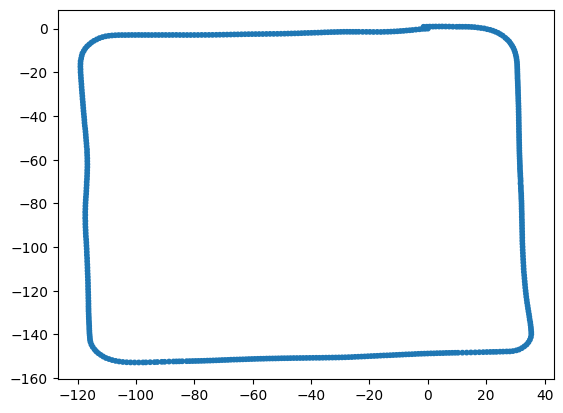

In [3]:
from common.FGVizHelpers import plot_points

plot_points(values.keys(), values)

In [ ]:
import kiss_icp.

In [9]:
a = {1: 24}

if a:
    print(True)
else:
    print(False)

True


In [7]:
from pathlib import Path

filePath = Path("./results/urban")
path2 = Path(filePath)
print(path2)

results/urban


# Check covariances for approximation of LinearContainerFactor

In [62]:
import re

def load_pose_cov_file(file_path):
    file_path = Path(file_path)
    records = []

    with file_path.open("r") as f:
        lines = f.readlines()

    # Skip the first line (header/info)
    for line in lines[1:]:
        line = line.strip()
        if not line:
            continue

        key_match = re.search(r"key:\s*([^\s]+)", line)
        pose_match = re.search(r"pose:\s*\[(.*?)\]\s*covariance:", line)
        cov_match = re.search(r"covariance:\s*\[(.*?)\]\s*$", line)

        if key_match is None or pose_match is None or cov_match is None:
            continue

        key = key_match.group(1)
        pose_flat = np.fromstring(pose_match.group(1), sep=" ")
        cov_flat = np.fromstring(cov_match.group(1), sep=" ")

        pose = pose_flat.reshape(4, 4)
        covariance = cov_flat.reshape(6, 6)

        records.append(
            {
                "key": key,
                "pose": pose,
                "covariance": covariance,
            }
        )

    return records


# Example usage
file_path_1 = Path("../denseMarginalization.txt")
data_dense = load_pose_cov_file(file_path_1)

print(f"Loaded {len(data_dense)} entries from {file_path_1}")
print(data_dense[0]["key"])
print(data_dense[0]["pose"])
print(data_dense[0]["covariance"])

Loaded 967 entries from ../denseMarginalization.txt
c1
[[  0.99987246   0.01446941   0.00676079   0.95251736]
 [ -0.01454014   0.99983881   0.01053259  -0.54256401]
 [ -0.0066073   -0.01062955   0.99992168 -18.22779908]
 [  0.           0.           0.           1.        ]]
[[  9.86960542  -0.          -0.           0.           0.03497395   0.32315493]
 [ -0.           9.8696054    0.          -0.03497395  -0.           9.99654359]
 [ -0.           0.           9.86960542  -0.32315493  -9.99654359   0.        ]
 [  0.          -0.03497395  -0.32315493 100.01080476   0.32731122  -0.03542377]
 [  0.03497395  -0.          -9.99654359   0.32731122 110.12533931   0.00114513]
 [  0.32315493   9.99654359   0.          -0.03542377   0.00114513 110.13579629]]


In [63]:
data_MuSigma = load_pose_cov_file(Path("../approxMargWithMuSigma.txt"))
data_Schur = load_pose_cov_file(Path("../approxMargWithSchurComp.txt"))

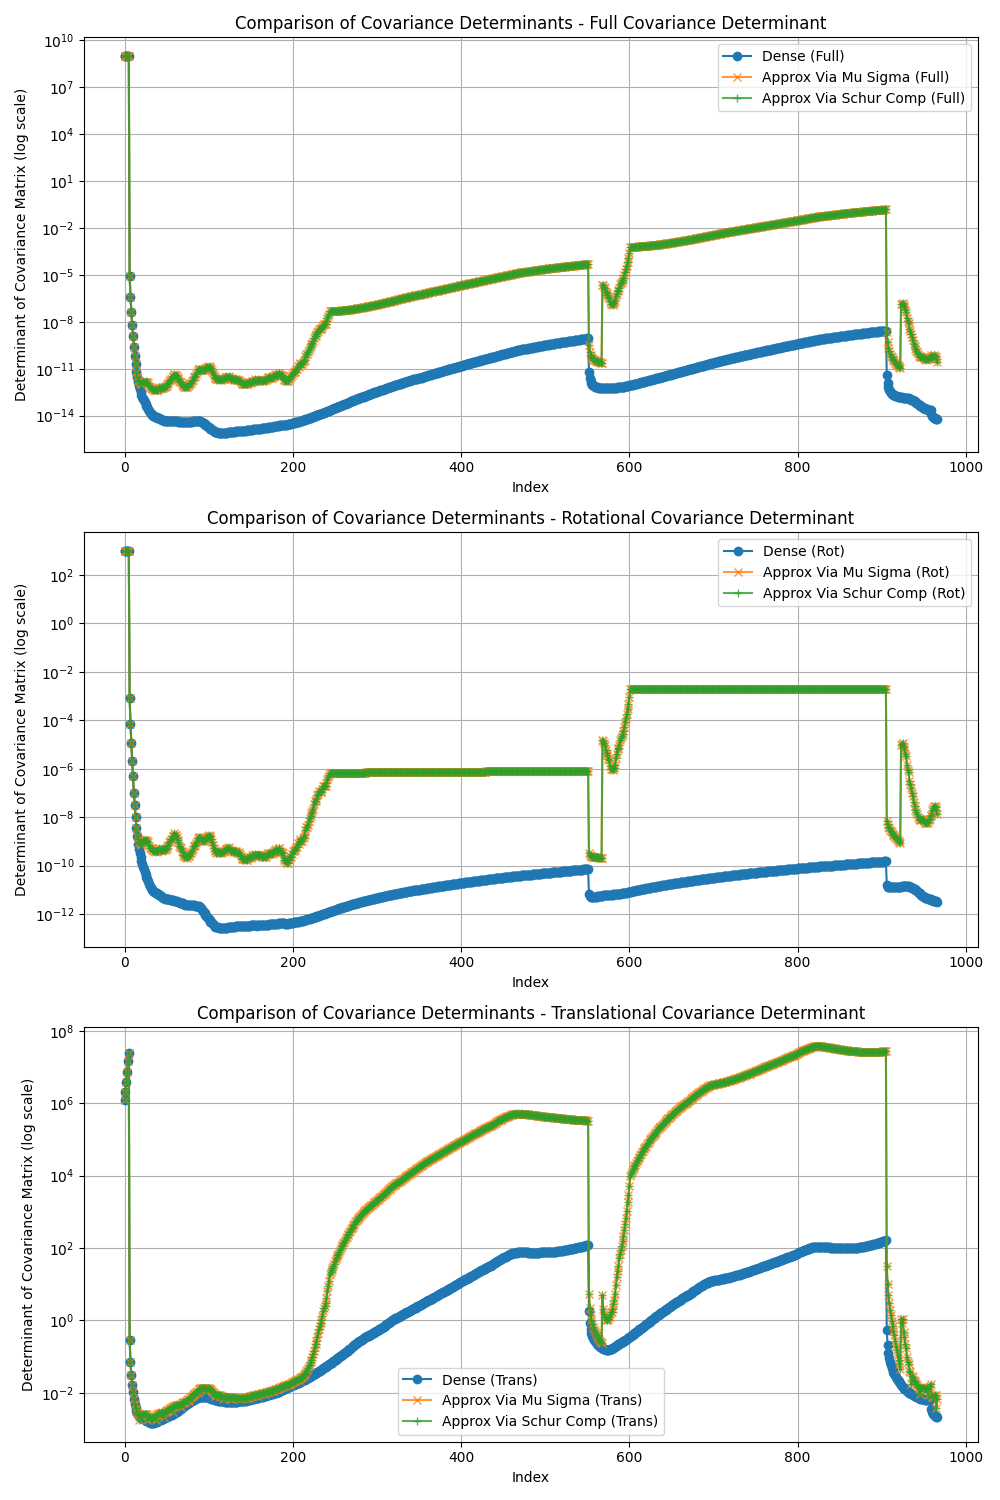

In [64]:
# Find determinant of covariance matrices and compare 
det_dense = []
det_dense.append([np.linalg.det(record["covariance"]) for record in data_dense]) # Full covariance determinant
det_dense.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_dense]) # Determinant of the top-left 3x3 block (rotational covariance)
det_dense.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_dense]) # Determinant of the bottom-right 3x3 block (translational covariance)

det_MuSigma = []
det_MuSigma.append([np.linalg.det(record["covariance"]) for record in data_MuSigma])
det_MuSigma.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_MuSigma]) # Determinant of the top-left 3x3 block (rotational covariance)
det_MuSigma.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_MuSigma]) # Determinant of the bottom-right 3x3 block (translational covariance)

det_Schur = []
det_Schur.append([np.linalg.det(record["covariance"]) for record in data_Schur])
det_Schur.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_Schur]) # Determinant of the top-left 3x3 block (rotational covariance)
det_Schur.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_Schur]) # Determinant of the bottom-right 3x3 block (translational covariance)


# Plot the determinants for comparison with a y axis in log scale
labels = ['Full', 'Rot', 'Trans']
titles = ['Full Covariance Determinant', 'Rotational Covariance Determinant', 'Translational Covariance Determinant']
fig, ax = plt.subplots(3, 1, figsize=(10, 15))
for i, (det1, det2, det3) in enumerate(zip(det_dense, det_MuSigma, det_Schur)):
    ax[i].set_yscale('log')
    ax[i].plot(det1, label=f'Dense ({labels[i]})', marker='o')
    ax[i].plot(det2, label=f'Approx Via Mu Sigma ({labels[i]})', alpha=0.8, marker='x')
    ax[i].plot(det3, label=f'Approx Via Schur Comp ({labels[i]})', alpha = 0.8, marker='+')
    ax[i].set_xlabel('Index')
    ax[i].set_ylabel('Determinant of Covariance Matrix (log scale)')
    ax[i].set_title(f'Comparison of Covariance Determinants - {titles[i]}')
    ax[i].legend()
    ax[i].grid()
plt.tight_layout()

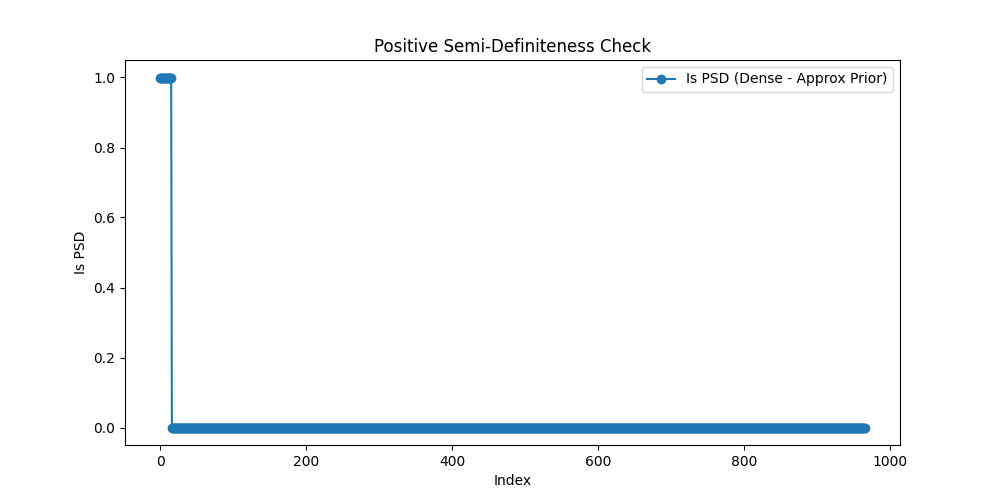

In [ ]:
import common.FGVizHelpers as fgtools
psd = []
for d1, d2 in zip(data_dense, data_MuSigma):
    cov1 = d1["covariance"]
    cov2 = d2["covariance"]
    psd.append(fgtools.isPSD(cov1 - cov2, printDebug=False))

plt.figure(figsize=(10, 5))
plt.plot(psd, label='Is PSD (Dense - Approx Prior)', marker='o')
plt.xlabel('Index')
plt.ylabel('Is PSD')
plt.title('Positive Semi-Definiteness Check')
plt.legend()

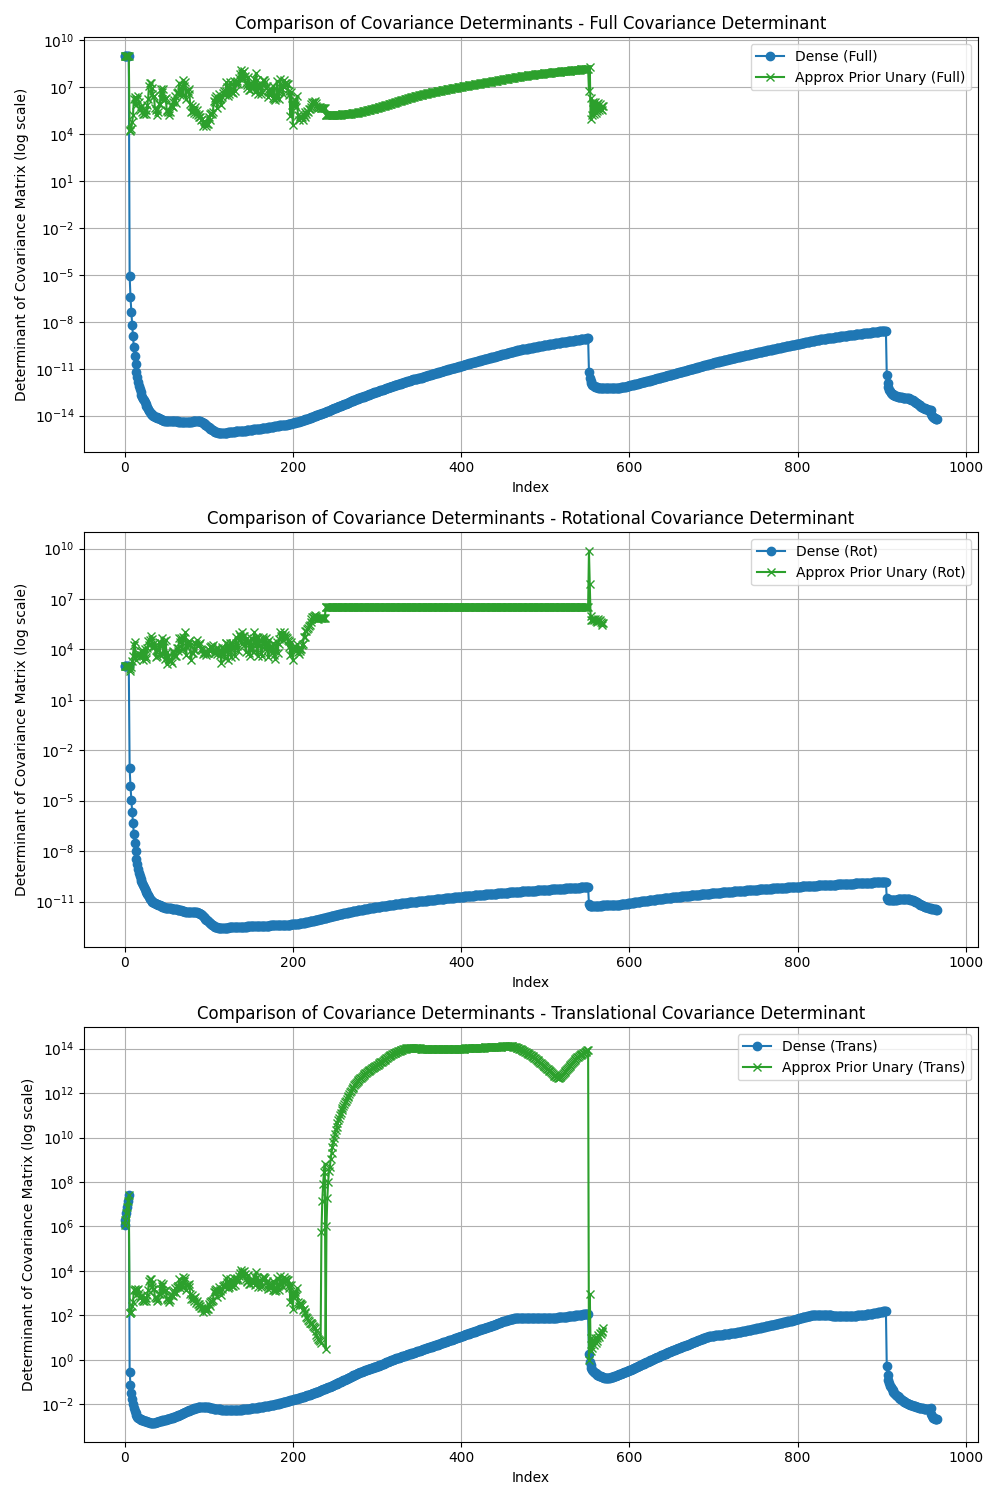

In [ ]:
file_path_3 = Path("../approxPrior.txt")
data_MuSigmaPrior = load_pose_cov_file(file_path_3)

det_MuSigmaPrior = []
det_MuSigmaPrior.append([np.linalg.det(record["covariance"]) for record in data_MuSigmaPrior])
det_MuSigmaPrior.append([np.linalg.det(record["covariance"][:3, :3]) for record in data_MuSigmaPrior]) # Determinant of the top-left 3x3 block (rotational covariance)
det_MuSigmaPrior.append([np.linalg.det(record["covariance"][3:, 3:]) for record in data_MuSigmaPrior]) # Determinant of the bottom-right 3x3 block (translational covariance)

# Plot the determinants for comparison with a y axis in log scale
labels = ['Full', 'Rot', 'Trans']
titles = ['Full Covariance Determinant', 'Rotational Covariance Determinant', 'Translational Covariance Determinant']
fig, ax = plt.subplots(3, 1, figsize=(10, 15))
for i, (det1, det2) in enumerate(zip(det_dense, det_MuSigmaPrior)):
    ax[i].set_yscale('log')
    ax[i].plot(det1, label=f'Dense ({labels[i]})', marker='o')
    ax[i].plot(det2, label=f'Approx Prior Unary ({labels[i]})', marker='x', color="tab:green")
    ax[i].set_xlabel('Index')
    ax[i].set_ylabel('Determinant of Covariance Matrix (log scale)')
    ax[i].set_title(f'Comparison of Covariance Determinants - {titles[i]}')
    ax[i].legend()
    ax[i].grid()
plt.tight_layout()

In [44]:
def readTimeFromFile(filename):
    with open(filename, "r") as f:
        lines = f.readlines()
        data = [float(line.strip()) for line in lines]
        return data
    

data_mu_sigma = readTimeFromFile("../approximationTime_MuSigma.txt")
data_schurcomplement = readTimeFromFile("../approximationTime_SchurComplement.txt")



In [43]:
print(data_mu_sigma)

[0.00011014938354492188, 0.00012946128845214844, 0.00021076202392578125, 0.00010347366333007812, 0.00012540817260742188, 0.00013566017150878906, 0.00010156631469726562, 0.00018548965454101562, 0.00013637542724609375, 0.00010323524475097656, 0.00012826919555664062, 0.00017070770263671875, 0.00022673606872558594, 0.00011849403381347656, 0.00013375282287597656, 0.00019669532775878906, 0.00021600723266601562, 0.0002002716064453125, 0.00024509429931640625, 0.0001342296600341797, 0.0001933574676513672, 0.00021886825561523438, 0.00010824203491210938, 0.00020956993103027344, 0.00010156631469726562, 0.00012159347534179688, 0.00012183189392089844, 0.00011706352233886719, 0.0002562999725341797, 0.000102996826171875, 0.00010371208190917969, 0.00010585784912109375, 0.00011587142944335938, 0.00015115737915039062, 0.00012683868408203125, 0.00010585784912109375, 0.0002079010009765625, 0.00014019012451171875, 0.00021409988403320312, 0.00020003318786621094, 0.00018358230590820312, 0.0002372264862060547,

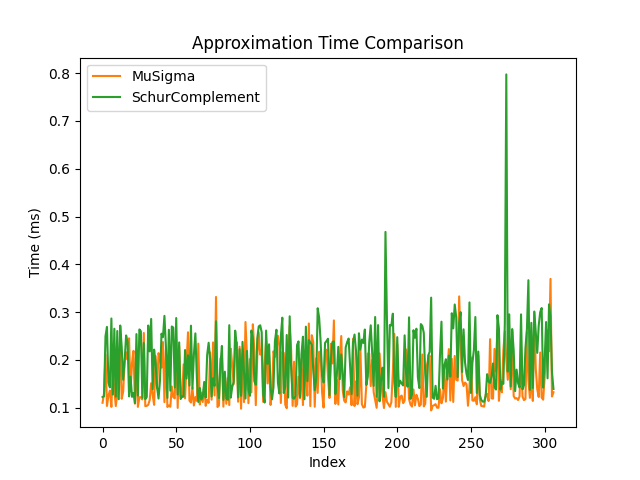

In [66]:
plt.close("Timing")
plt.figure("Timing")
plt.plot(np.asarray(data_mu_sigma)*1e3, label="MuSigma", color="tab:orange")
plt.plot(np.asarray(data_schurcomplement)*1e3, label="SchurComplement", color="tab:green")
plt.title("Approximation Time Comparison")
plt.xlabel("Index")
plt.ylabel("Time (ms)")
plt.legend()
plt.show()

In [ ]:
# Used in debug console to check covariances
key1 = gtsam.Symbol('B', 0).key()
key2 = gtsam.Symbol('A', 6).key()
jointmarginal = updater.combined.fixedLagSmoother.getISAM2().jointMarginalCovariance([key1, key2])
relCov = fgtools.getRelativeCov(tmpValues.atPose3(key1), tmpValues.atPose3(key2), jointmarginal.fullMatrix())

params = Params()
threshold = params.relativeCovariancePolicy.threshold
det_rel = np.linalg.det(relCov[:3,:3])
relVar = np.diag(relCov)

if params.relativeCovariancePolicy.debug:
    print(f"Relative covariance between keys \"{gtsam.Symbol(key1).string()}\" and \"{gtsam.Symbol(key2).string()}\"")
    print(f"  x: {relVar[0]} y: {relVar[1]} z: {relVar[2]} det: {det_rel}")

if relVar[0] > threshold[0] or relVar[1] > threshold[1] or relVar[2] > threshold[2] or det_rel > threshold[3]:
    if params.relativeCovariancePolicy.debug:
        print(f"Relative covariance too big between keys \"{gtsam.Symbol(key1).string()}\" and \"{gtsam.Symbol(key2).string()}\"")
        print(f"relVal > Threshold")
        print(f"x: {relVar[0]} > {threshold[0]} -> {relVar[0] > threshold[0]}")
        print(f"y: {relVar[1]} > {threshold[1]} -> {relVar[1] > threshold[1]}")
        print(f"z: {relVar[2]} > {threshold[2]} -> {relVar[2] > threshold[2]}")
        print(f"det: {det_rel} > {threshold[3]} -> {det_rel   > threshold[3]}")


In [67]:
from collections import deque

# Create a queue with a fixed size of 3
# (Using 3 here just to make the example easy to read)
my_queue = deque(maxlen=3)

# Add elements
my_queue.append(1)
my_queue.append(2)
my_queue.append(3)
print(f"Queue is full: {list(my_queue)}") 
# Output: [1, 2, 3]

# Adding a 4th element automatically drops the oldest one (1)
my_queue.append(4)
print(f"After adding 4: {list(my_queue)}") 
# Output: [2, 3, 4]

my_queue.append(5)
print(f"After adding 5: {list(my_queue)}") 
# Output: [3, 4, 5]

Queue is full: [1, 2, 3]
After adding 4: [2, 3, 4]
After adding 5: [3, 4, 5]


In [69]:
list_a = [1, 2, 3, 4, 5]
list_b = [6, 6, 7, 8, 9]

# Convert the list you are checking AGAINST into a set
set_b = set(list_b)

# Check if any element from list_a is in set_b
has_overlap = any(item in set_b for item in list_a)

print(has_overlap)  # Output: True

False


In [25]:
key = gtsam.Symbol('x', 1).key()

# new_key = gtsam.LabeledSymbol(ord('x'), ord('A'), 0)
new_key = gtsam.LabeledSymbol(key)
# new_key = new_key.newLabel(ord('A'))

print(f"Key: {key}, Labeled Key: {str(new_key)}, Labeled Key's key: {new_key.key()}")
print(f"key chr: {chr(new_key.chr())}, label chr: {new_key.label()}, index: {new_key.index()}")

Key: 8646911284551352321, Labeled Key: : x
, Labeled Key's key: 8646911284551352321
key chr: x, label chr: 0, index: 1


In [28]:
key = gtsam.LabeledSymbol(ord('x'), ord('1'), 0)
print(str(key))

: x10



In [38]:
a = [1, 2, 3, None, 4, 5, 6, 7, 8, 9, None, 10]
if not np.all(a):
    print("There is at least one None value in the list.")


There is at least one None value in the list.


In [7]:
graph = gtsam_unstable.deserializeGraphFromFile("../results/nc/quad-easy/graph.gtsam")
keys = graph.keys()

244

In [19]:
values = gtsam_unstable.deserializeValuesFromFile("../results/nc/quad-easy/values.gtsam")
len(values.keys())

244

In [18]:
keySet = gtsam.KeySet(values.keys())
keySet.size()

244

In [21]:
np.load("../information.npy")

array([[ 0., -0.,  0., -0.,  0.,  0.],
       [-0., -0., -0., -0.,  0.,  0.],
       [ 0., -0.,  0., -0.,  0.,  0.],
       [-0., -0., -0.,  0., -0.,  0.],
       [ 0.,  0.,  0., -0.,  0., -0.],
       [ 0.,  0.,  0.,  0., -0., -0.]])

In [24]:
T_w_o = gtsam.Pose2(
    1.0, 2.0, np.deg2rad(90)
)

T_w_r = gtsam.Pose2(
    2.0, 1.0, np.deg2rad(45)
)

T_rel_o = gtsam.Pose2(
    1.0, 0.0, np.deg2rad(0)
)

T_w_o2 = T_w_o.compose(T_rel_o)
print(T_w_o2)


T_w_r2 = T_w_r.compose(T_rel_o)
print(T_w_r2)


(1, 3, 1.5708)

(2.70711, 1.70711, 0.785398)



In [11]:
arr = np.array([[11, 12, 13],
                [21, 22, 23],
                [31, 32, 33]])

prior_indices = [1]
current_indices = [2, 0]

# for i in range(3):
#     if i == 2:
#         prior_indices.append(i)
#     else:
#         current_indices.append(i)

Gpp = arr[np.ix_(prior_indices, prior_indices)]
Gpc = arr[np.ix_(prior_indices, current_indices)]
Gcc = arr[np.ix_(current_indices, current_indices)]

print("Gpp:\n", Gpp)
print("Gpc:\n", Gpc)
print("Gcc:\n", Gcc)

Gpp:
 [[22]]
Gpc:
 [[23 21]]
Gcc:
 [[33 31]
 [13 11]]


In [ ]:
lidar_topics = {
    "/os_cloud_node/points",
    "/ouster_top/points",
    "/ouster/points",
}

valid_topics = {
    *lidar_topics
}

valid_topics

{'/os_cloud_node/points', '/ouster/points', '/ouster_top/points'}

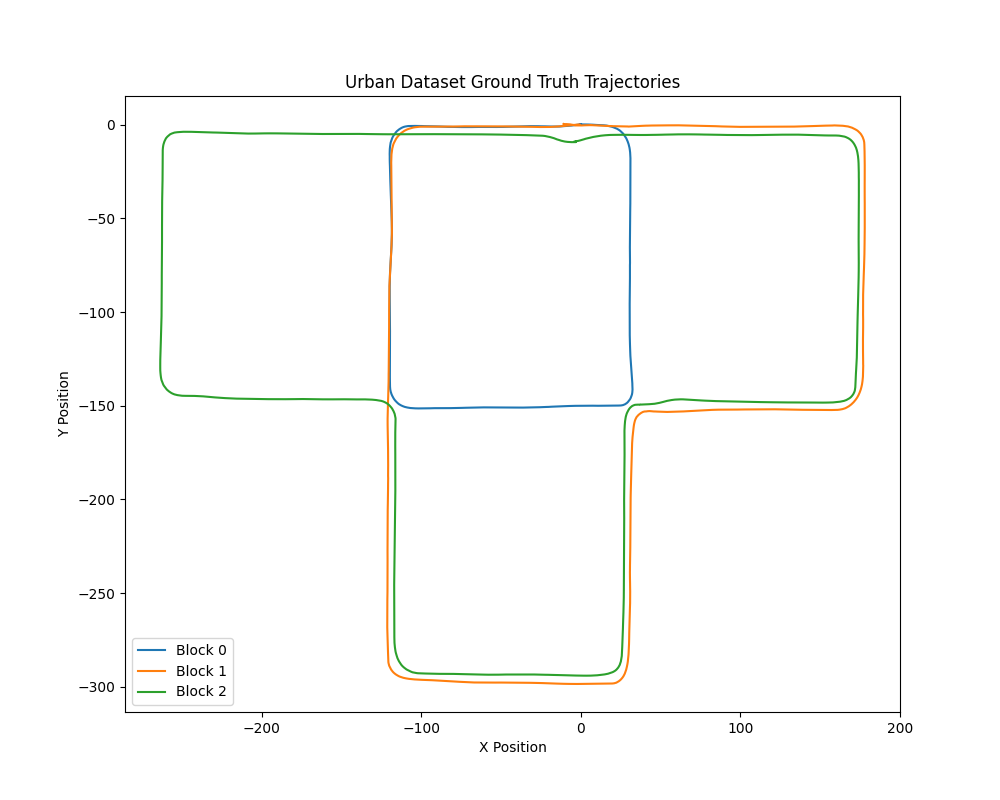

In [7]:
# Visualize ground truth data for urban dataset
gt_dir = Path("/home/benb/data_byu/bags/urban/groundTruth")
gt1 = GroundTruthLoader(gt_dir / "block0_gt" / "optimized_poses.txt")
gt2 = GroundTruthLoader(gt_dir / "block1_gt" / "optimized_poses.txt")
gt3 = GroundTruthLoader(gt_dir / "block2_gt" / "optimized_poses.txt")

plt.figure(figsize=(10, 8))
plt.plot(gt1.gt_df["x"], gt1.gt_df["y"], label="Block 0", color="tab:blue")
plt.plot(gt2.gt_df["x"], gt2.gt_df["y"], label="Block 1", color="tab:orange")
plt.plot(gt3.gt_df["x"], gt3.gt_df["y"], label="Block 2", color="tab:green")
plt.title("Urban Dataset Ground Truth Trajectories")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.legend()

🚀 Data stream detected. Initializing framework estimators
Reached 60 seconds in data stream loop.
Reached 120 seconds in data stream loop.
Reached 180 seconds in data stream loop.


Text(0.5, 1.0, 'Urban Block 0 Timestamps')

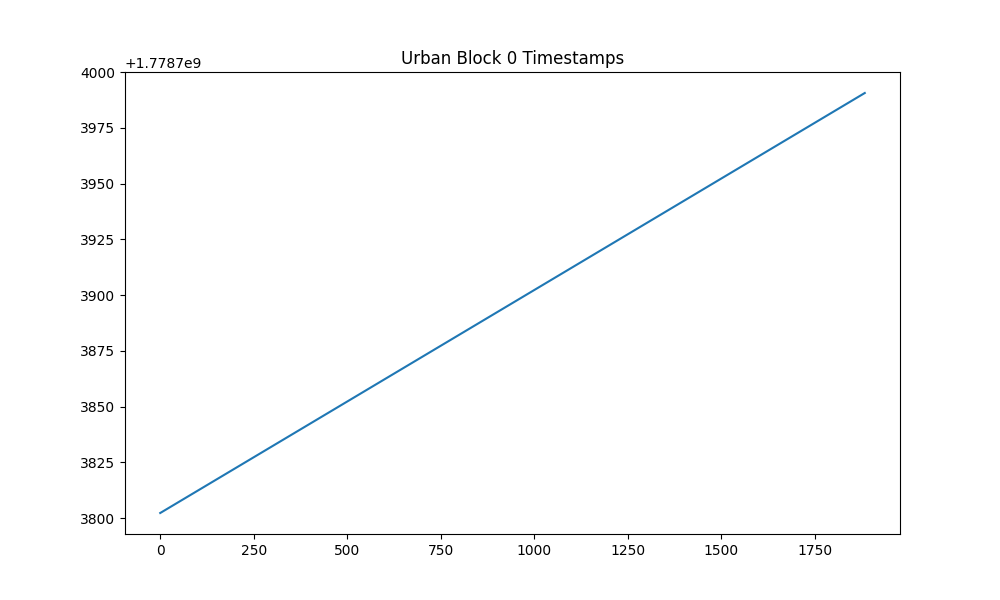

In [ ]:
bagReader = ReadTopicsFromRosbag(Path("/home/benb/data_byu/bags/urban/block0"))
timestamps = []

for topic, timestamp, xyz_points in bagReader.next_message():
    if timestamps:
        if timestamp <= timestamps[-1]:
            print(f"\033[93mWarning: Timestamp {timestamp} is not greater than the previous timestamp {timestamps[-1]}.\033[0m")
    timestamps.append(timestamp)
    # View with Open3D
    # pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(xyz_points))
    # break

# o3d.visualization.draw_geometries([pcd], window_name="Urban Block 0 Point Cloud", width=800, height=600)

plt.figure(figsize=(10, 6))
plt.plot(timestamps, label="Timestamps", color="tab:blue")
plt.title("Urban Block 0 Timestamps")

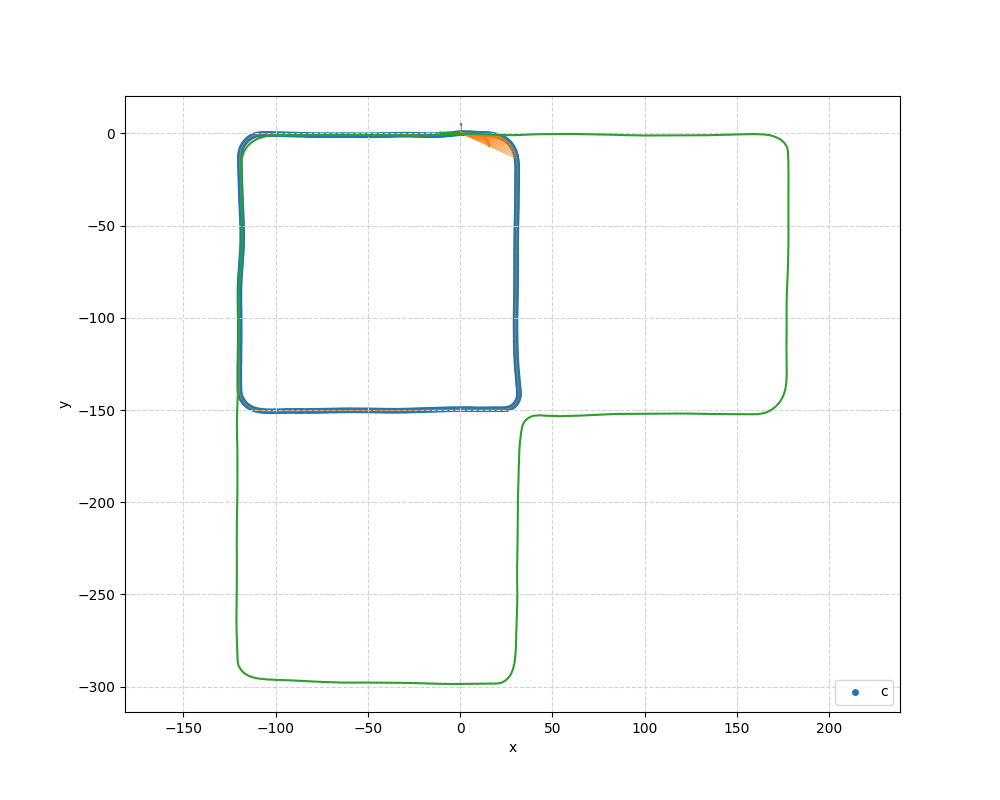

In [4]:
gt = GroundTruthLoader(Path("/home/benb/data_byu/bags/urban/groundTruth/block1_gt/optimized_poses.txt"))
prior_graph = gtsam_unstable.deserializeGraphFromFile("../results/urban/block0/graph.gtsam")
prior_values = gtsam_unstable.deserializeValuesFromFile("../results/urban/block0/values.gtsam")

ax = fgtools.plot_graph(prior_graph, prior_values, addKeyLabels=False, changeColorBySymbols=True)
ax.plot(gt.gt_df["x"], gt.gt_df["y"], label="Ground Truth", color="tab:green")

In [ ]:
gtsam.noiseModel.Diagonal.Sigmas